# 03 - Model: how much do promotions add, per segment?

**Client question:** are our promotions actually increasing sales, in which stores and situations, and which should we keep, change or stop?

Stage 2 compared promo days with non-promo days. That can mislead: promos might simply fall on busier days. Here a model predicts daily sales from **store, weekday, month, holidays and Promo**,
then asks "what would this store's sales have been on the same day *with* and *without* the promo?". The gap is the promo uplift, with those other factors held fixed.

Design choices that protect against leakage and over-claiming:
- **Time-based split, never random:** train on the past, tune on a 6-week validation slice, and score once on the final 6 weeks (the honest test).
- **`Customers` is not a feature.** It is a *result* of the promotion and unknown when you forecast, so using it would fake accuracy and hide the promo effect.
- **`is_sales_outlier` is not a feature.** It is computed from Sales itself.
- **Two baselines to beat**, so we can say what the model adds.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
import mlflow
from pathlib import Path
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression

SEED = 42
np.random.seed(SEED)
CLEAN, ANALYTICS, DOCS = Path("../data/clean"), Path("../data/analytics"), Path("../docs")
FIG = DOCS / "figures"
for p in (ANALYTICS, FIG):
    p.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CLEAN / "sales_clean.csv", parse_dates=["Date"]).sort_values(["Date", "Store"]).reset_index(drop=True)
df["WeekOfYear"] = df.Date.dt.isocalendar().week.astype(int)
df["DayOfMonth"] = df.Date.dt.day
print(df.shape, df.Date.min().date(), "->", df.Date.max().date())

2026/09/19 06:42:57 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at <project>/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


(38037, 24) 2013-01-01 -> 2015-07-31


## 1. Time-based split

Rossmann forecasts up to 6 weeks ahead, so the last 6 weeks are the test set and the 6 weeks before that are the validation set (used only to decide when to stop training).

In [2]:
TEST_START = df.Date.max() - pd.Timedelta(days=41)   # last 6 weeks
VAL_START = TEST_START - pd.Timedelta(days=42)       # the 6 weeks before that

train = df[df.Date < VAL_START]
val = df[(df.Date >= VAL_START) & (df.Date < TEST_START)]
test = df[df.Date >= TEST_START]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(part):6,d} rows  {part.Date.min().date()} -> {part.Date.max().date()}")
assert train.Date.max() < val.Date.min() and val.Date.max() < test.Date.min()  # strictly past -> future
fit_df = pd.concat([train, val])  # everything before the test window: used for the baselines and the final refit

train 34,508 rows  2013-01-01 -> 2015-05-08
val    1,705 rows  2015-05-09 -> 2015-06-19
test   1,824 rows  2015-06-20 -> 2015-07-31


## 2. Features and metrics

Categories are declared once so every split shares the same encoding. Metrics: **MAE** (average error in euros), **MAPE** (average % error) and **RMSPE**
(the Rossmann competition's own metric, which punishes big % misses).

In [3]:
CAT = ["Store", "StoreType", "Assortment", "StateHoliday"]
NUM = ["Promo", "DayOfWeek", "Month", "WeekOfYear", "DayOfMonth", "SchoolHoliday", "CompetitionDistance", "Promo2"]
FEATURES = CAT + NUM
cat_types = {c: pd.CategoricalDtype(sorted(df[c].unique())) for c in CAT}


def make_X(d):
    X = d[FEATURES].copy()
    for c in CAT:
        X[c] = X[c].astype(cat_types[c])
    return X


def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": mean_absolute_error(y, p),
            "MAPE_pct": float(np.mean(np.abs(y - p) / y) * 100),
            "RMSPE": float(np.sqrt(np.mean(((y - p) / y) ** 2)))}

## 3. Baselines

1. **Store x weekday average** - "this store's typical Tuesday", ignores promotions.
2. **Store x weekday x promo average** - the same but knows about promotions. If LightGBM cannot beat this, the model adds nothing beyond simple averages.

Both are fit on everything before the test window (train + validation), the same data the final model gets, so the comparison is fair.

In [4]:
def group_mean_predict(train_df, target_df, keys):
    means = train_df.groupby(keys).Sales.mean().rename("pred")
    pred = target_df[keys].merge(means, on=keys, how="left")["pred"]
    fallback = target_df[["Store"]].merge(train_df.groupby("Store").Sales.mean().rename("s"), on="Store", how="left")["s"]
    return pred.fillna(fallback).to_numpy()


base1 = group_mean_predict(fit_df, test, ["Store", "DayOfWeek"])
base2 = group_mean_predict(fit_df, test, ["Store", "DayOfWeek", "Promo"])
m_base1, m_base2 = metrics(test.Sales, base1), metrics(test.Sales, base2)
print("baseline 1 (store x weekday):        ", {k: round(v, 3) for k, v in m_base1.items()})
print("baseline 2 (store x weekday x promo):", {k: round(v, 3) for k, v in m_base2.items()})

baseline 1 (store x weekday):         {'MAE': 1215.069, 'MAPE_pct': 17.086, 'RMSPE': 0.213}
baseline 2 (store x weekday x promo): {'MAE': 730.203, 'MAPE_pct': 10.103, 'RMSPE': 0.128}


## 4. LightGBM (predicts log of sales)

Log-sales is used because promotions and weekdays scale sales by a percentage rather than adding a fixed amount, and it keeps a big store from dominating the error.
The validation slice decides how many trees to grow (early stopping). The model is then **refit on train + validation** with that tree count, so it learns from the most recent weeks, and the test slice is scored once at the end.

In [5]:
params = dict(objective="regression", n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=20,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, deterministic=True,
              force_row_wise=True, verbose=-1)
model_es = lgb.LGBMRegressor(**params)
model_es.fit(make_X(train), np.log1p(train.Sales),
             eval_set=[(make_X(val), np.log1p(val.Sales))],
             callbacks=[lgb.early_stopping(50, verbose=False)])
best_iter = model_es.best_iteration_
print("best iteration:", best_iter)
val_pred = np.expm1(model_es.predict(make_X(val)))  # validation score comes from the model that has not seen val

model = lgb.LGBMRegressor(**{**params, "n_estimators": best_iter})
model.fit(make_X(fit_df), np.log1p(fit_df.Sales))    # final model: same tree count, trained on train + val
test_pred = np.expm1(model.predict(make_X(test)))
m_val, m_lgb = metrics(val.Sales, val_pred), metrics(test.Sales, test_pred)
print("validation:", {k: round(v, 3) for k, v in m_val.items()})
print("test:      ", {k: round(v, 3) for k, v in m_lgb.items()})

results = pd.DataFrame({"store x weekday": m_base1, "store x weekday x promo": m_base2, "LightGBM": m_lgb}).T
beats = m_lgb["MAE"] < m_base2["MAE"]
verdict = (f"LightGBM {'beats' if beats else 'does NOT beat'} the store x weekday x promo baseline "
           f"(MAE {m_lgb['MAE']:,.0f} vs {m_base2['MAE']:,.0f}; MAPE {m_lgb['MAPE_pct']:.1f}% vs {m_base2['MAPE_pct']:.1f}%)")
print(verdict)
results.round(3)

<project>/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


best iteration: 334


validation: {'MAE': 880.344, 'MAPE_pct': 11.425, 'RMSPE': 0.144}
test:       {'MAE': 769.446, 'MAPE_pct': 10.619, 'RMSPE': 0.134}
LightGBM does NOT beat the store x weekday x promo baseline (MAE 769 vs 730; MAPE 10.6% vs 10.1%)


,MAE,MAPE_pct,RMSPE
store x weekday,1215.069,17.086,0.213
store x weekday x promo,730.203,10.103,0.128
LightGBM,769.446,10.619,0.134


**Reading the table (lower is better on all three metrics):**
- LightGBM cuts the error by about a third compared with the naive "store x weekday" average (MAE 1,215 -> 769), so promotions and calendar effects matter for forecasting.
- It does **not** beat the promo-aware average (MAE 730, about 5% better than LightGBM). With only 50 stores and about a year of history, each store's average for a weekday and promo state already captures most of the signal,
  and a bigger model has little extra to learn. The honest claim is "comparable accuracy", not "the model wins".
- Test error (10.6%) is close to validation error (11.4%), which is a good sign. A test error far *below* validation would be a leakage warning, not good news.
- So the model's job here is **not** to beat the average at forecasting. It is to give a promo uplift with month, holiday and weekday held fixed, which the next sections check against two simpler methods.

## 5. Forecast vs actual (held-out 6 weeks)

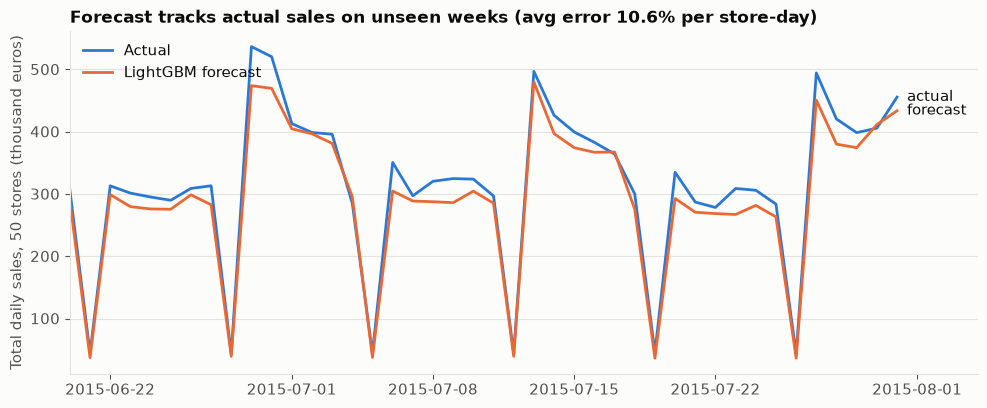

In [6]:
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3de"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

scored = test[["Date", "Store", "StoreType", "DayOfWeek", "Promo", "Sales"]].copy()
scored["pred_baseline"] = base2
scored["pred_lgbm"] = test_pred
daily = scored.groupby("Date")[["Sales", "pred_lgbm"]].sum()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(daily.index, daily.Sales / 1000, color=BLUE, linewidth=2, label="Actual")
ax.plot(daily.index, daily.pred_lgbm / 1000, color=ORANGE, linewidth=2, label="LightGBM forecast")
ax.text(daily.index[-1], daily.Sales.iloc[-1] / 1000, "  actual", color=INK, va="center")
ax.text(daily.index[-1], daily.pred_lgbm.iloc[-1] / 1000, "  forecast", color=INK, va="center")
ax.set_ylabel("Total daily sales, 50 stores (thousand euros)")
ax.set_title(f"Forecast tracks actual sales on unseen weeks (avg error {m_lgb['MAPE_pct']:.1f}% per store-day)")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(daily.index[0], daily.index[-1] + pd.Timedelta(days=4))
fig.tight_layout()
fig.savefig(FIG / "04_forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** the forecast follows the weekly rhythm (Sunday closures, the Monday peak) closely, but sits below actual sales on most days: the model under-predicts by roughly 5-10% in these weeks.
Sales were rising into the summer and the model, trained on earlier months, lags that trend. A bias check like this matters more than the average error alone.

## 6. What the model relies on

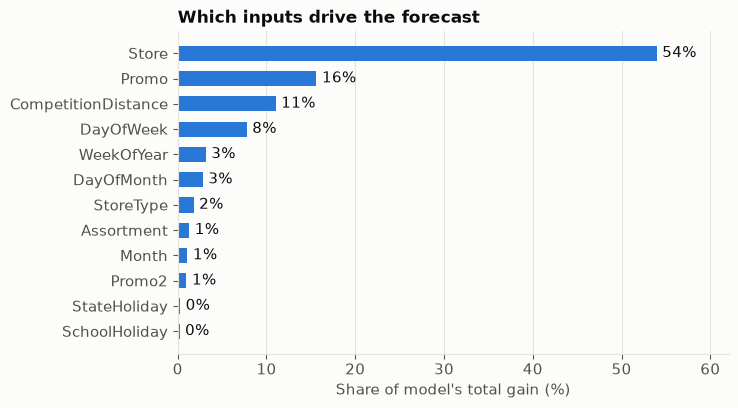

{'Store': 54.0, 'Promo': 15.6, 'CompetitionDistance': 11.0, 'DayOfWeek': 7.8, 'WeekOfYear': 3.2, 'DayOfMonth': 2.8, 'StoreType': 1.8, 'Assortment': 1.3, 'Month': 1.1, 'Promo2': 1.0, 'StateHoliday': 0.3, 'SchoolHoliday': 0.2}


In [7]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in imp.values], padding=4, color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlabel("Share of model's total gain (%)")
ax.set_xlim(0, imp.max() * 1.15)
ax.set_title("Which inputs drive the forecast")
fig.tight_layout()
fig.savefig(FIG / "05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.sort_values(ascending=False).round(1).to_dict())

**Reading the chart:** `Store` dominates because each store has its own sales level. `CompetitionDistance` shows about 11% only because it is constant per store, so it acts as a second store ID and shares the "store identity" signal;
it does **not** mean competition drives sales (Stage 2 showed it does not change promo lift). `Promo` is the largest input that changes from day to day, which is what we want for an uplift question.

## 7. Promo uplift with everything else held fixed

For every Mon-Fri row of the **held-out weeks**, the model predicts sales twice: once with `Promo=1` and once with `Promo=0`, changing nothing else (same store, same day, same holidays).
The gap is the promo effect the model attributes to that store-day. Stage 2 compared different days, so this is a second, independent opinion.

Two cross-checks: (a) the Stage 2 style store-vs-itself number, and (b) a plain linear regression with store, weekday, month and holiday adjustments, whose Promo coefficient converts to a % uplift.

In [8]:
tw = test[test.DayOfWeek <= 5].copy()  # promos never run at weekends
tw["pred_promo"] = np.expm1(model.predict(make_X(tw.assign(Promo=1))))
tw["pred_nopromo"] = np.expm1(model.predict(make_X(tw.assign(Promo=0))))
tw["incremental"] = tw.pred_promo - tw.pred_nopromo

overall_uplift = (tw.pred_promo.sum() / tw.pred_nopromo.sum() - 1) * 100
print(f"LightGBM counterfactual uplift (held-out Mon-Fri): {overall_uplift:+.1f}%")

# cross-check (a): Stage 2 style, store vs itself on all Mon-Fri data
wk = df[df.DayOfWeek <= 5]
bs = wk.groupby(["Store", "Promo"]).Sales.mean().unstack()
bs["eda_uplift"] = (bs[1] / bs[0] - 1) * 100
meta = df.groupby("Store").agg(StoreType=("StoreType", "first"), CompetitionDistance=("CompetitionDistance", "first"))
bs = bs.join(meta)
eda_uplift = wk.groupby("Promo").Sales.mean().pipe(lambda m: (m[1] / m[0] - 1) * 100)
print(f"Stage 2 style uplift (pooled Mon-Fri, all data):    {eda_uplift:+.1f}%")

# cross-check (b): linear regression on log sales with store/weekday/month/holiday adjustments
lin_cols = ["Store", "DayOfWeek", "Month", "StateHoliday", "SchoolHoliday"]
Xl = pd.get_dummies(fit_df[lin_cols].astype(str)).assign(Promo=fit_df.Promo.values)
lin = LinearRegression().fit(Xl, np.log1p(fit_df.Sales))
lin_uplift = (np.exp(lin.coef_[list(Xl.columns).index("Promo")]) - 1) * 100
print(f"Linear regression (adjusted) uplift:                {lin_uplift:+.1f}%")

LightGBM counterfactual uplift (held-out Mon-Fri): +35.2%
Stage 2 style uplift (pooled Mon-Fri, all data):    +37.7%
Linear regression (adjusted) uplift:                +38.6%


## 8. Uplift by segment (the numbers the decision memo will use)

In [9]:
bs["dist_band"] = pd.qcut(bs.CompetitionDistance, 4, labels=["Closest", "Near", "Far", "Farthest"])
tw = tw.merge(bs[["dist_band"]], left_on="Store", right_index=True, how="left")


def segment_table(by, label):
    rows = []
    for key, g in tw.groupby(by, observed=True):
        promo_days = g[g.Promo == 1]
        rows.append({
            "segment_type": label, "segment": str(key), "stores": g.Store.nunique(),
            "model_uplift_pct": (g.pred_promo.sum() / g.pred_nopromo.sum() - 1) * 100,
            "promo_days_run": len(promo_days),
            "avg_extra_sales_per_promo_day": promo_days.incremental.mean(),
            "total_extra_sales_holdout": promo_days.incremental.sum(),
        })
    return pd.DataFrame(rows)


seg = pd.concat([segment_table("StoreType", "store_type"), segment_table("dist_band", "competition_distance")], ignore_index=True)
seg["eda_uplift_pct"] = seg.apply(
    lambda r: bs[bs.StoreType == r.segment].eda_uplift.mean() if r.segment_type == "store_type"
    else bs[bs.dist_band == r.segment].eda_uplift.mean(), axis=1)
seg.round(1)

,segment_type,segment,stores,model_uplift_pct,promo_days_run,avg_extra_sales_per_promo_day,total_extra_sales_holdout,eda_uplift_pct
0,store_type,a,24,37.2,360,2414.9,869376.4,40.8
1,store_type,b,4,19.6,60,1432.2,85931.9,20.5
2,store_type,c,8,38.0,120,2063.4,247608.8,46.1
3,store_type,d,14,35.3,210,2147.9,451059.7,38.9
4,competition_distance,Closest,13,32.9,195,2468.3,481311.8,39.3
5,competition_distance,Near,12,36.5,180,2017.3,363113.5,41.6
6,competition_distance,Far,12,36.3,180,2028.0,365042.2,38.4
7,competition_distance,Farthest,13,36.0,195,2279.5,444509.2,38.8


**Reading the table:** `model_uplift_pct` (held-fixed, held-out weeks) and `eda_uplift_pct` (Stage 2, store vs itself) use different methods and different time windows, so they will not match exactly.
What matters is whether they **agree on the pattern**: is type b still the weakest, and does competitor distance still make no difference?
`avg_extra_sales_per_promo_day` is the extra sales (euros) the model attributes to a promo day; it is revenue, not profit, because promotion cost is not in the data.

## 9. Save outputs for Power BI and the decision memo

In [10]:
scored.to_csv(ANALYTICS / "predictions_test.csv", index=False)
seg.round(2).to_csv(ANALYTICS / "uplift_by_segment.csv", index=False)
print("saved:", [p.name for p in sorted(ANALYTICS.glob("*.csv"))])

saved: ['predictions_test.csv', 'uplift_by_segment.csv']


## 10. Track the runs in MLflow

In [11]:
mlflow.set_tracking_uri("sqlite:///" + str((Path("..") / "mlflow.db").resolve()))
EXP = "promo_effectiveness"
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=(Path("..") / "mlartifacts").resolve().as_uri())
mlflow.set_experiment(EXP)

split_info = {"train_end": str(train.Date.max().date()), "val_start": str(VAL_START.date()), "test_start": str(TEST_START.date())}

with mlflow.start_run(run_name="baseline_store_weekday_promo"):
    mlflow.log_params({"model": "group mean", "keys": "Store,DayOfWeek,Promo", **split_info})
    mlflow.log_metrics({f"test_{k}": v for k, v in m_base2.items()})

with mlflow.start_run(run_name="lightgbm_log_sales"):
    mlflow.log_params({**{k: v for k, v in params.items() if k not in ("verbose", "n_estimators")}, "features": ",".join(FEATURES), "n_estimators": best_iter,
                       "target": "log1p(Sales)", "best_iteration": best_iter, **split_info})
    mlflow.log_metrics({**{f"val_{k}": v for k, v in m_val.items()}, **{f"test_{k}": v for k, v in m_lgb.items()},
                        "promo_uplift_pct_model": overall_uplift, "promo_uplift_pct_linear": lin_uplift,
                        "promo_uplift_pct_eda": eda_uplift})
    mlflow.log_artifact(str(FIG / "04_forecast_vs_actual.png"))
    mlflow.log_artifact(str(FIG / "05_feature_importance.png"))
    mlflow.log_artifact(str(ANALYTICS / "uplift_by_segment.csv"))
print("logged 2 runs to experiment:", EXP)

2026/09/19 06:43:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/19 06:43:01 INFO mlflow.store.db.utils: Updating database tables


logged 2 runs to experiment: promo_effectiveness


## Caveats (say these out loud)
- **The uplift is model-based, not a randomised experiment.** It holds store, weekday, month and holidays fixed, but if managers ran promos on days they already expected to be busy for reasons not in the data,
  part of the "uplift" is not caused by the promo. Agreement between three different methods raises confidence but does not prove cause.
- **Six held-out weeks is a short window,** and segment results for type b rest on only 4 stores.
- **Revenue, not profit:** promotion cost and margin are not in the data.
- **Single train/val/test split.** A rolling-origin evaluation would be more robust with more time.

## Write the model results for the docs folder

In [12]:
def md_table(frame):
    cols = list(frame.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in frame.iterrows():
        out.append("| " + " | ".join(f"{v:,.1f}" if isinstance(v, float) else str(v) for v in r) + " |")
    return out


seg_show = seg.rename(columns={"model_uplift_pct": "model uplift %", "eda_uplift_pct": "Stage 2 uplift %",
                               "avg_extra_sales_per_promo_day": "extra sales / promo day (EUR)",
                               "total_extra_sales_holdout": "extra sales, 6 wks (EUR)", "promo_days_run": "promo days"})
seg_show = seg_show[["segment_type", "segment", "stores", "promo days", "model uplift %", "Stage 2 uplift %",
                     "extra sales / promo day (EUR)", "extra sales, 6 wks (EUR)"]]
res = results.reset_index().rename(columns={"index": "model"})
res["MAE"] = res["MAE"].map("{:,.0f}".format)
res["MAPE_pct"] = res["MAPE_pct"].map("{:.1f}".format)
res["RMSPE"] = res["RMSPE"].map("{:.3f}".format)

lines = [
    "# Model results",
    "",
    "Generated by `notebooks/03_model.ipynb`. Runs are tracked in MLflow (experiment `promo_effectiveness`).",
    "",
    "## Setup",
    f"- Data: `data/clean/sales_clean.csv`, 50 stores. Target: daily Sales (model predicts log1p(Sales)).",
    f"- Time-based split: train up to {train.Date.max().date()}, validation {VAL_START.date()} to {(TEST_START - pd.Timedelta(days=1)).date()} (early stopping only), "
    f"test {TEST_START.date()} to {test.Date.max().date()} (last 6 weeks, scored once).",
    "- Features: " + ", ".join(FEATURES) + ". `CompetitionDistance` is constant per store, so its importance in the model mostly reflects store identity, not a competition effect.",
    "- Deliberately excluded: `Customers` (a result of the promotion and unknown at forecast time) and `is_sales_outlier` (derived from Sales). Both would leak the answer.",
    "",
    "## Forecast accuracy on the held-out 6 weeks",
    *md_table(res),
    "",
    f"**{verdict}.**",
    "- It clearly beats the naive store x weekday average, but is comparable to (not better than) the promo-aware average: with 50 stores and about a year of history, simple averages already capture most of the signal. "
    "The model's value here is the uplift estimate with other factors held fixed, not forecasting accuracy." if not beats else "- It improves on both simple averages.",
    f"LightGBM validation MAPE was {m_val['MAPE_pct']:.1f}% vs test MAPE {m_lgb['MAPE_pct']:.1f}%; similar values mean the test result is not a lucky or leaked number.",
    "",
    "## Promo uplift (everything else held fixed)",
    f"- LightGBM counterfactual (same store-day with vs without promo, held-out Mon-Fri): **{overall_uplift:+.1f}%**.",
    f"- Stage 2 store-vs-itself comparison (all data, Mon-Fri): {eda_uplift:+.1f}%.",
    f"- Linear regression with store, weekday, month and holiday adjustments: {lin_uplift:+.1f}%.",
    "- Three different methods giving similar answers raises confidence in the size of the effect.",
    "",
    "- Bias check: on the held-out weeks the forecast sits below actual sales on most days (roughly 5-10% under), because sales were rising into the summer and the model lags the trend.",
    "",
    "## Uplift by segment",
    *md_table(seg_show),
    "",
    "Extra sales are revenue in euros over the 6 held-out weeks for the 50-store sample, not profit (no promotion cost in the data).",
    "",
    "## Caveats",
    "- Model-based estimate, not a randomised experiment: promotions may have been scheduled on days expected to be busy.",
    "- Six held-out weeks and 50 stores; type b rests on 4 stores.",
    "- Revenue, not profit: promotion cost and margin are not available.",
    "",
    "## Production mapping",
    "- Training/tracking here is local LightGBM + open-source MLflow; in production this maps to Azure ML (training, model registry, endpoints) with data prepared in Databricks/Azure Data Factory.",
]
(DOCS / "model_results.md").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

# Model results

Generated by `notebooks/03_model.ipynb`. Runs are tracked in MLflow (experiment `promo_effectiveness`).

## Setup
- Data: `data/clean/sales_clean.csv`, 50 stores. Target: daily Sales (model predicts log1p(Sales)).
- Time-based split: train up to 2015-05-08, validation 2015-05-09 to 2015-06-19 (early stopping only), test 2015-06-20 to 2015-07-31 (last 6 weeks, scored once).
- Features: Store, StoreType, Assortment, StateHoliday, Promo, DayOfWeek, Month, WeekOfYear, DayOfMonth, SchoolHoliday, CompetitionDistance, Promo2. `CompetitionDistance` is constant per store, so its importance in the model mostly reflects store identity, not a competition effect.
- Deliberately excluded: `Customers` (a result of the promotion and unknown at forecast time) and `is_sales_outlier` (derived from Sales). Both would leak the answer.

## Forecast accuracy on the held-out 6 weeks
| model | MAE | MAPE_pct | RMSPE |
|---|---|---|---|
| store x weekday | 1,215 | 17.1 | 0.213 |
| store x weekd